# Sistem Rekomendasi Wisata Berbasis Konten dengan Sentence-BERT dan Filter Musim

**Artikel:** *Sistem Rekomendasi Destinasi Wisata Berbasis Konten Menggunakan Sentence-BERT dan Filter Musim pada Ulasan Pengunjung*

| Penulis | NIM |
|---|---|
| Ar'raffi Abqori Nur Azizi | 230441100026 *(dari proposal sebelumnya; cek ulang)* |
| Isma' Yafa Nur Zamzami Ramadhani | `[isi NIM]` |
| Muhammad Maulana Khanif | `[isi NIM]` |
| Andika Kamaluddin | `[isi NIM]` |

## Fokus notebook
Notebook ini membangun **satu sistem**: rekomendasi destinasi berbasis konten yang memakai **Sentence-BERT (SBERT)** sebagai representasi teks ulasan.

```
Ulasan -> bersihkan -> SBERT (dibekukan) -> vektor ulasan
       -> rata-rata per destinasi        -> profil destinasi (dinormalisasi L2)
Kueri teks / destinasi favorit -> SBERT -> cosine similarity -> filter musim -> Top-K
```

**Apakah ini perbandingan model?** Bukan. Sistemnya hanya satu (SBERT). **TF-IDF dipertahankan hanya sebagai pembanding acuan**, supaya angka SBERT dapat ditafsirkan: tanpa acuan, nilai seperti Hit@10 = 0,48 tidak bisa dinilai bagus atau buruk. Pembanding acak juga dilaporkan. Bila tidak diperlukan, set `RUN_PEMBANDING = False`.

## Yang dievaluasi (khusus untuk sistem rekomendasi)
| Protokol | Pertanyaan | Metrik |
|---|---|---|
| **A** | Apakah ulasan dapat dikembalikan ke destinasinya? Juga **dengan nama destinasi disamarkan** agar tidak sekadar mencocokkan nama | Hit@K, MRR@10 |
| **B** | Apakah destinasi yang mirip memang sejenis (kategori sama)? | Precision@K, NDCG@K |
| **C** | Apakah hasil layak untuk musim yang dipilih? | season violation rate |
| **D** | Apakah rekomendasi beragam atau menumpuk pada sedikit destinasi? | cakupan katalog, Gini, kategori unik, korelasi popularitas |
| **E** | Apakah kueri teks pendek (seperti yang diketik pengguna) mengembalikan kategori yang tepat? | Precision@10 per kategori |

## Isi
1 Pemasangan dan konfigurasi · 2 Memuat data · 3 Pembersihan · 4 Label dan eksplorasi · 5 Embedding SBERT dan biaya · 6 Profil dan rekomendasi · 7 Evaluasi · 8 Uji statistik dan analisis · 9 Contoh rekomendasi · 10 Grafik · 11 Simpan artefak · 12 Uji muat ulang · 13 Unduh hasil

> **Penting.** Model SBERT butuh internet untuk diunduh sekali. Jika SBERT tidak tersedia, notebook **berhenti dengan pesan jelas** (tidak diam-diam memakai pengganti), kecuali `ALLOW_DEMO = True`, yaitu mode uji alur yang hasilnya **tidak boleh** dipakai di artikel.

## 1. Pemasangan dan konfigurasi

Jalankan sel pemasangan satu kali. Pengaturan yang bisa diubah ada di sel kedua. **Model utama** dipilih lewat `MODEL_UTAMA`; model SBERT lain bersifat opsional (`SBERT_AKTIF`).

In [1]:
%pip install -q sentence-transformers ftfy gdown requests scikit-learn pandas numpy scipy matplotlib joblib openpyxl psutil

In [2]:
import os, re, io, json, time, math, warnings, platform, importlib
from pathlib import Path
from datetime import datetime
import numpy as np
import pandas as pd
import joblib
import matplotlib
import matplotlib.pyplot as plt
from scipy import sparse
from scipy.stats import wilcoxon, spearmanr
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD, PCA
from sklearn.preprocessing import normalize

warnings.filterwarnings("ignore")

# ============================ KONFIGURASI ============================
GDRIVE_ID = "1Sos4dG_WlMxM9LN7NnOs6bx1IN7erU1a"     # ID berkas Google Drive
LOCAL_NAME = "koreksi_dataset.xlsx"
LOCAL_CANDIDATES = [LOCAL_NAME, f"/content/{LOCAL_NAME}", f"/content/drive/MyDrive/{LOCAL_NAME}",
                    f"/mnt/user-data/uploads/{LOCAL_NAME}"]
TRY_DRIVE = True              # False = jangan coba mengunduh dari Google Drive
ALLOW_DEMO = False            # True hanya untuk menguji alur tanpa data/SBERT (hasil TIDAK boleh dipakai di artikel)

COLS = {"dest": "destinasi", "text": "text_original", "season": "rekomendasi_cuaca", "cat": "wisata", "rating": "rating"}
CANDIDATES = {
    "dest":   ["destinasi", "nama_destinasi", "destination", "place", "nama_tempat", "nama_wisata"],
    "text":   ["text_original", "review_text", "ulasan", "review", "teks"],
    "season": ["rekomendasi_cuaca", "musim", "season", "label_musim"],
    "cat":    ["wisata", "kategori", "category", "jenis_wisata"],
    "rating": ["rating", "skor", "stars", "bintang"],
}

# ---- Model SBERT (sistem utama) ----
SBERT_MODELS = {
    "indo":   {"label": "indo-sentence-bert", "name": "firqaaa/indo-sentence-bert-base", "pool": "mean"},
    "minilm": {"label": "MiniLM multibahasa", "name": "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2", "pool": "mean"},
}
SBERT_AKTIF = ["indo"]        # tambahkan "minilm" bila ingin model SBERT kedua (opsional, hanya untuk ablasi)
MODEL_UTAMA = "indo"          # model yang dijadikan sistem rekomendasi dan dianalisis rinci
RUN_PEMBANDING = True         # TF-IDF sebagai pembanding acuan (bukan tujuan penelitian)

SEED = 42
SEEDS = [42, 43, 44]
PROFILE_FRAC = 0.8             # 80% ulasan per destinasi membentuk profil, 20% menjadi kueri uji
MIN_WORDS = 3                  # ulasan dengan kata kurang dari ini dibuang (pilihan penulis; laporkan)
MIN_REVIEWS_PER_DEST = 10      # destinasi dengan ulasan lebih sedikit dibuang (pilihan penulis; laporkan)
MAX_LEN = 128                  # panjang masukan maksimum (token) untuk encoder SBERT
INCLUDE_SAMPLES = True         # False bila teks ulasan mentah tidak boleh disebarkan (cek izin data)
SEASON_ALL = "Kemarau & Penghujan"   # destinasi layak sepanjang tahun (INTERPRETASI; konfirmasi ke pembuat data)
TOPK = 10
# =====================================================================

assert MODEL_UTAMA in SBERT_AKTIF, "MODEL_UTAMA harus termasuk SBERT_AKTIF"
ART = Path("artifacts")
(ART / "figures").mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"font.size": 9, "axes.spines.top": False, "axes.spines.right": False, "axes.titlesize": 10, "figure.dpi": 100})
print("Python", platform.python_version(), "| numpy", np.__version__, "| pandas", pd.__version__)
print("Model utama:", SBERT_MODELS[MODEL_UTAMA]["name"], "| pembanding TF-IDF:", RUN_PEMBANDING)

Python 3.13.18 | numpy 2.4.6 | pandas 2.2.3
Model utama: firqaaa/indo-sentence-bert-base | pembanding TF-IDF: True


## 2. Memuat data (otomatis)

**Urutan pencarian:** (1) berkas lokal `koreksi_dataset.xlsx`; (2) unduh dari Google Drive lewat `GDRIVE_ID`; (3) di Colab, dialog unggah manual. Agar unduhan otomatis berhasil, atur berbagi berkas ke **"Anyone with the link"**.

In [3]:
def _is_xlsx(p):
    try:
        with open(p, "rb") as f:
            return f.read(4) == b"PK\x03\x04"
    except OSError:
        return False


def download_from_drive(dest=LOCAL_NAME):
    log = []
    try:
        import gdown
        gdown.download(id=GDRIVE_ID, output=dest, quiet=True)
        if _is_xlsx(dest):
            return dest, log + ["gdown: berhasil"]
        log.append("gdown: hasil bukan xlsx (kemungkinan akses belum 'Anyone with the link')")
    except Exception as e:
        log.append(f"gdown: {type(e).__name__}")
    try:
        import requests
        for u in (f"https://drive.google.com/uc?export=download&id={GDRIVE_ID}",
                  f"https://docs.google.com/spreadsheets/d/{GDRIVE_ID}/export?format=xlsx"):
            host = u.split("/")[2]
            try:
                r = requests.get(u, timeout=90)
                if r.status_code == 200 and r.content[:4] == b"PK\x03\x04":
                    open(dest, "wb").write(r.content)
                    return dest, log + [f"requests ({host}): berhasil"]
                log.append(f"requests ({host}): HTTP {r.status_code}, bukan xlsx")
            except Exception as e:
                log.append(f"requests ({host}): {type(e).__name__}")
    except ImportError:
        log.append("requests tidak terpasang")
    return None, log


def locate_data():
    for p in LOCAL_CANDIDATES:
        if Path(p).is_file() and _is_xlsx(p):
            return p, "berkas lokal"
    if TRY_DRIVE:
        path, log = download_from_drive()
        if path:
            return path, "Google Drive"
        print("Unduhan otomatis gagal:\n  - " + "\n  - ".join(log))
    try:
        from google.colab import files
        print("\nSilakan unggah koreksi_dataset.xlsx:")
        up = files.upload()
        for name in up:
            if name.lower().endswith(".xlsx"):
                os.replace(name, LOCAL_NAME)
                return LOCAL_NAME, "unggah manual"
    except ImportError:
        pass
    return None, "tidak ditemukan"


def make_demo_data(seed=SEED):
    # Data tiruan HANYA untuk menguji alur. Sebagian ulasan menyebut kata khas nama destinasi.
    rng = np.random.RandomState(seed)
    themes = {"pantai": "pasir ombak sunset laut perahu angin", "pegunungan": "gunung kabut dingin puncak tenda",
              "sejarah": "candi museum sejarah tradisi batik", "taman": "bunga anak bermain rumput keluarga"}
    words = "Sowan Prigi Klayar Ngliyep Bletok Mutiara Kedung Tumpang Papuma Bentar Teluk Gayasan Watukarung Sedudo Irenggolo Panataran Kresek".split()
    common = "bagus indah ramai bersih mahal seru nyaman sepi parkir tiket".split()
    rows, no = [], 0
    for cat, ws in themes.items():
        w = ws.split()
        for j in range(12):
            no += 1
            nm = f"{cat.title()} {words[(no * 3) % len(words)]}{chr(97 + j)}"
            tok = nm.split()[1]
            season = "Kemarau" if no % 2 else SEASON_ALL
            for _ in range(rng.randint(25, 60)):
                toks = [cat] + list(rng.choice(w, rng.randint(2, 4))) + list(rng.choice(common, rng.randint(1, 3)))
                if rng.rand() < 0.15:
                    toks.append(tok)
                rng.shuffle(toks)
                rows.append({"destinasi": nm, "text_original": " ".join(toks), "rating": int(rng.choice([5, 5, 4, 3, 1])),
                             "wisata": cat, "rekomendasi_cuaca": season})
    return pd.DataFrame(rows)


t0 = time.perf_counter()
data_path, data_source = locate_data()
if data_path is None:
    if not ALLOW_DEMO:
        raise FileNotFoundError("Data tidak ditemukan. Buka akses Drive ('Anyone with the link'), atau unggah "
                                f"{LOCAL_NAME}, atau set ALLOW_DEMO=True hanya untuk menguji alur.")
    raw, DEMO, data_source = make_demo_data(), True, "data tiruan"
    print("MODE DEMO: data tiruan. Hasil TIDAK boleh dipakai di artikel.")
else:
    raw, DEMO = pd.read_excel(data_path), False
    print(f"Data dimuat dari: {data_source} ({data_path}) dalam {time.perf_counter() - t0:.1f} dtk")
print("Bentuk data mentah:", raw.shape, "| kolom:", list(raw.columns))
raw.head(3)

Data dimuat dari: Google Drive (koreksi_dataset.xlsx) dalam 37.2 dtk
Bentuk data mentah: (79514, 8) | kolom: ['id_destinasi', 'destinasi', 'rating', 'date', 'text_original', 'text_preprocessed', 'rekomendasi_cuaca', 'wisata']


,id_destinasi,destinasi,rating,date,text_original,text_preprocessed,rekomendasi_cuaca,wisata
0,1,Air Dolo,4,1 hari lalu,bisa turun ga bisa naik ðŸ˜­ â€¦,turun naik,Kemarau & Penghujan,air terjun
1,1,Air Dolo,5,Diedit 4 hari lalu,"Belakangan saya cuma nongkrong di warung,Sanga...",belakang cuma nongkrong warungsangat lelah tur...,Kemarau & Penghujan,air terjun
2,1,Air Dolo,5,5 hari lalu,"air terjun yg bagus di lereng gunung wilis, un...",air terjun bagus lereng gunung wilis tuju air ...,Kemarau & Penghujan,air terjun


In [4]:
def resolve_columns(df):
    lower = {c.lower(): c for c in df.columns}
    out = {}
    for key, cands in CANDIDATES.items():
        manual = COLS.get(key)
        if manual and manual in df.columns:
            out[key] = manual
            continue
        found = next((lower[c] for c in cands if c in lower), None)
        if found is None and key != "rating":
            raise KeyError(f"Kolom '{key}' tidak ditemukan. Isi COLS['{key}']. Kolom tersedia: {list(df.columns)}")
        out[key] = found
    return out


col_map = resolve_columns(raw)
print("Pemetaan kolom:", col_map)
use = {v: k for k, v in col_map.items() if v is not None}
df = raw[list(use)].rename(columns=use).copy()
df.head(3)

Pemetaan kolom: {'dest': 'destinasi', 'text': 'text_original', 'season': 'rekomendasi_cuaca', 'cat': 'wisata', 'rating': 'rating'}


,dest,text,season,cat,rating
0,Air Dolo,bisa turun ga bisa naik ðŸ˜­ â€¦,Kemarau & Penghujan,air terjun,4
1,Air Dolo,"Belakangan saya cuma nongkrong di warung,Sanga...",Kemarau & Penghujan,air terjun,5
2,Air Dolo,"air terjun yg bagus di lereng gunung wilis, un...",Kemarau & Penghujan,air terjun,5


## 3. Pembersihan data

| Langkah | Alasan |
|---|---|
| Kembalikan penanda kontrol Excel `_x008d_` ke karakter aslinya | Karakter itu adalah *byte* penyusun emoji; **tidak boleh dibuang** sebelum `ftfy` merekonstruksinya |
| Perbaiki mojibake (`ðŸ˜­` menjadi 😭) | Kesalahan pengodean saat pengambilan data (`ftfy`) |
| Hapus tanda pemotongan di akhir ulasan | Sumber memotong ulasan panjang; tanda ini bukan isi ulasan |
| Buang ulasan kosong, terlalu pendek, dan duplikat | Tidak membawa informasi; duplikat membobot profil tidak adil |
| Buang destinasi dengan ulasan sedikit | Profil dari sedikit ulasan tidak stabil |

Teks yang dipakai adalah `text_original`, **bukan** `text_preprocessed`, karena SBERT membutuhkan kalimat yang utuh. `MIN_WORDS` dan `MIN_REVIEWS_PER_DEST` adalah **pilihan penulis**; laporkan nilainya dan jumlah yang terbuang.

In [5]:
XESC = re.compile(r"_x([0-9A-Fa-f]{4})_")
CTRL = re.compile(r"[\x00-\x08\x0b-\x1f\x7f-\x9f]")
MOJI = re.compile("Ã|â€|ðŸ|Â|Ð")


def pre_excel(t):
    return XESC.sub(lambda m: chr(int(m.group(1), 16)), t)


try:
    import ftfy
    ENC_METHOD = f"ftfy {ftfy.__version__}"
    def _fix(t):
        return CTRL.sub(" ", ftfy.fix_text(pre_excel(t)))
except ImportError:
    ENC_METHOD = "heuristik cp1252 (pasang ftfy untuk hasil lebih baik)"
    def _fix(t):
        t = pre_excel(t)
        if MOJI.search(t):
            try:
                t = t.encode("cp1252").decode("utf-8")
            except Exception:
                pass
        return CTRL.sub(" ", t)

print("Perbaikan encoding:", ENC_METHOD)
for s in ["bisa turun ga bisa naik ðŸ˜­ â€¦", "lamaÂ² disana"]:
    print(ascii(s[:45]), "->", ascii(_fix(s)[:45]))

Perbaikan encoding: ftfy 6.3.1
'bisa turun ga bisa naik \xf0\u0178\u02dc\xad \xe2\u20ac\xa6' -> 'bisa turun ga bisa naik \U0001f62d \u2026'
'lama\xc2\xb2 disana' -> 'lama\xb2 disana'


In [6]:
n_raw = len(df)
null_text = int(df["text"].isna().sum())
df = df.dropna(subset=["text", "dest"]).copy()
df["text"] = df["text"].astype(str)
moji_before = int(df["text"].str.contains(MOJI).sum())
xesc_before = int(df["text"].str.contains(XESC).sum())

t0 = time.perf_counter()
need = df["text"].str.contains(r"[^\x00-\x7f]|_x[0-9A-Fa-f]{4}_", regex=True)
df.loc[need, "text"] = df.loc[need, "text"].map(_fix)
df["text"] = df["text"].str.replace(r"\s+", " ", regex=True).str.strip()
n_truncated = int(df["text"].str.contains(r"(?:…|\.\.\.)\s*$", regex=True).sum())
df["text"] = df["text"].str.replace(r"\s*(?:…|\.\.\.)\s*$", "", regex=True).str.strip()
moji_after = int(df["text"].str.contains(MOJI).sum())
print(f"Perbaikan teks selesai dalam {time.perf_counter() - t0:.1f} dtk")

n_a = len(df)
df = df[df["text"].str.split().str.len() >= MIN_WORDS]
n_b = len(df)
df = df.drop_duplicates(subset=["dest", "text"])
n_c = len(df)
cnt = df.groupby("dest").size()
dest_before = int(cnt.shape[0])
df = df[df["dest"].isin(cnt[cnt >= MIN_REVIEWS_PER_DEST].index)].reset_index(drop=True)

clean_report = {
    "ulasan_mentah": n_raw, "teks_kosong": null_text, "mojibake_sebelum": moji_before, "mojibake_sesudah": moji_after,
    "penanda_excel_sebelum": xesc_before, "ulasan_terpotong_google": n_truncated,
    "dibuang_terlalu_pendek": n_a - n_b, "dibuang_duplikat": n_b - n_c,
    "dibuang_destinasi_kecil": int(n_c - len(df)), "destinasi_dibuang": dest_before - int(df["dest"].nunique()),
    "ulasan_akhir": int(len(df)), "destinasi_awal": dest_before, "destinasi_akhir": int(df["dest"].nunique()),
    "metode_encoding": ENC_METHOD, "MIN_WORDS": MIN_WORDS, "MIN_REVIEWS_PER_DEST": MIN_REVIEWS_PER_DEST,
}
pd.Series(clean_report, name="nilai").to_frame()

Perbaikan teks selesai dalam 10.5 dtk


,nilai
ulasan_mentah,79514
teks_kosong,10
mojibake_sebelum,15693
mojibake_sesudah,0
penanda_excel_sebelum,3543
ulasan_terpotong_google,16960
dibuang_terlalu_pendek,12366
dibuang_duplikat,96
dibuang_destinasi_kecil,38
destinasi_dibuang,5


## 4. Pemeriksaan label dan eksplorasi

**Pemeriksaan wajib:** apakah tiap destinasi hanya punya **satu** label musim dan **satu** kategori? Jika ya, label melekat pada destinasi, sehingga evaluasi memakai pembagian **per destinasi** (bagian 7), bukan acak per ulasan. Perhatikan juga **hubungan musim dan kategori**: bila sebagian kategori hampir seluruhnya berlabel sama, filter musim sekaligus menyaring kategori. Itu perlu dibahas sebagai keterbatasan.

In [7]:
for lab in ["season", "cat"]:
    mx = int(df.groupby("dest")[lab].nunique().max())
    print(f"{lab:7s}: maks nilai unik per destinasi = {mx} -> " + ("OK, satu nilai per destinasi" if mx == 1 else "PERHATIAN: ada destinasi dengan >1 nilai; dipakai nilai terbanyak"))


def mode_of(s):
    return s.mode().iat[0]


agg = {"n_reviews": ("text", "size"), "season": ("season", mode_of), "cat": ("cat", mode_of)}
if "rating" in df.columns:
    agg["rating_mean"] = ("rating", "mean")
meta = df.groupby("dest").agg(**agg).sort_index()
dest_names = list(meta.index)
n_dest = len(dest_names)
d_index = {n: i for i, n in enumerate(dest_names)}
dest_idx = df["dest"].map(d_index).values
groups = {i: np.where(dest_idx == i)[0] for i in range(n_dest)}
cats = meta["cat"].values
SEASONS = sorted(meta["season"].unique().tolist())

words = df["text"].str.split().str.len()
data_stats = {
    "n_reviews": int(len(df)), "n_dest": int(n_dest), "n_cat": int(meta["cat"].nunique()),
    "reviews_per_dest": {"min": int(meta.n_reviews.min()), "median": float(meta.n_reviews.median()), "mean": round(float(meta.n_reviews.mean()), 1), "max": int(meta.n_reviews.max())},
    "words": {"median": float(words.median()), "mean": round(float(words.mean()), 1), "p95": float(np.percentile(words, 95)), "max": int(words.max())},
    "season_counts": meta["season"].value_counts().to_dict(), "cat_counts": meta["cat"].value_counts().to_dict(),
    "season_by_cat": pd.crosstab(meta["cat"], meta["season"]).to_dict("index"),
    "rating_counts": {int(k): int(v) for k, v in df["rating"].value_counts().sort_index().items()} if "rating" in df.columns else {},
}
print(f"\nDestinasi: {n_dest} | ulasan: {len(df):,} | kategori: {data_stats['n_cat']}")
print("Ulasan per destinasi:", data_stats["reviews_per_dest"])
print("Panjang ulasan (kata):", data_stats["words"])
pd.crosstab(meta["cat"], meta["season"])

season : maks nilai unik per destinasi = 1 -> OK, satu nilai per destinasi
cat    : maks nilai unik per destinasi = 1 -> OK, satu nilai per destinasi

Destinasi: 202 | ulasan: 67,004 | kategori: 14
Ulasan per destinasi: {'min': 10, 'median': 297.5, 'mean': 331.7, 'max': 1330}
Panjang ulasan (kata): {'median': 12.0, 'mean': 15.7, 'p95': 39.0, 'max': 66}


season,Kemarau,Kemarau & Penghujan
cat,,
air terjun,8,14
danau/waduk,5,4
desa/kampung wisata,0,6
goa,8,0
hutan/perkebunan,8,6
lainnya,4,4
pantai,29,15
pegunungan,15,7
pemandian,2,1


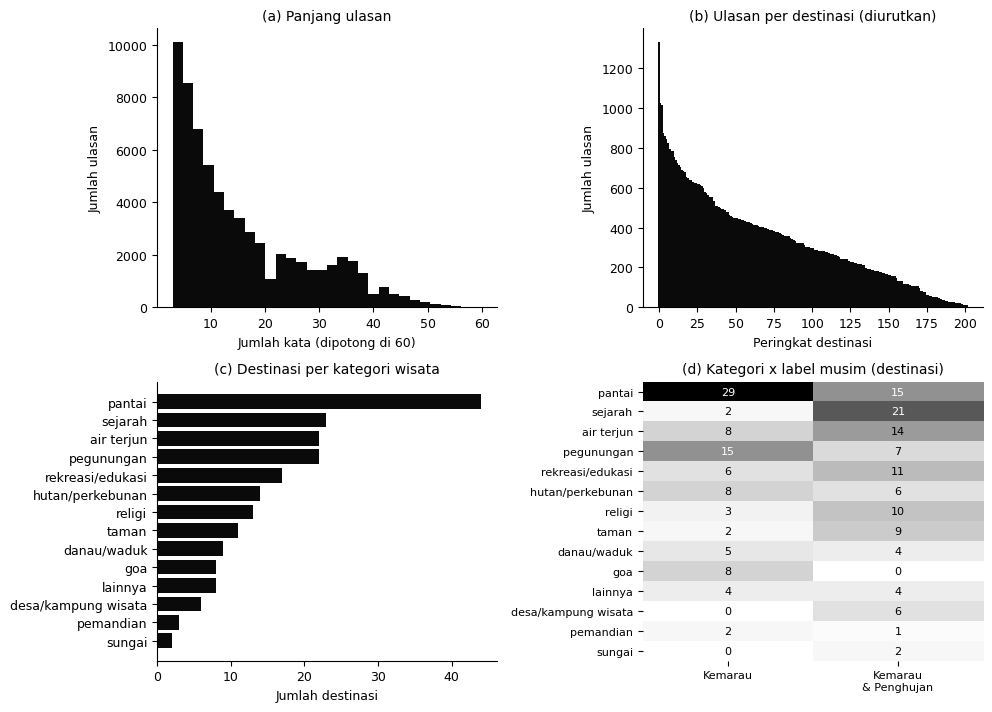

In [8]:
fig, ax = plt.subplots(2, 2, figsize=(10, 7.2))
ax[0, 0].hist(words.clip(upper=60), bins=30, color="#0a0a0a")
ax[0, 0].set(title="(a) Panjang ulasan", xlabel="Jumlah kata (dipotong di 60)", ylabel="Jumlah ulasan")
order = meta["n_reviews"].sort_values(ascending=False)
ax[0, 1].bar(range(len(order)), order.values, color="#0a0a0a", width=1.0)
ax[0, 1].set(title="(b) Ulasan per destinasi (diurutkan)", xlabel="Peringkat destinasi", ylabel="Jumlah ulasan")
cc = meta["cat"].value_counts().sort_values()
ax[1, 0].barh(cc.index, cc.values, color="#0a0a0a")
ax[1, 0].set(title="(c) Destinasi per kategori wisata", xlabel="Jumlah destinasi")
ct = pd.crosstab(meta["cat"], meta["season"]).loc[cc.index[::-1]]
ax[1, 1].imshow(ct.values, cmap="Greys", aspect="auto")
ax[1, 1].set_xticks(range(len(ct.columns)))
ax[1, 1].set_xticklabels([c.replace(" & ", "\n& ") for c in ct.columns], fontsize=8)
ax[1, 1].set_yticks(range(len(ct.index)))
ax[1, 1].set_yticklabels(ct.index, fontsize=8)
for i in range(ct.shape[0]):
    for j in range(ct.shape[1]):
        v = int(ct.values[i, j])
        ax[1, 1].text(j, i, v, ha="center", va="center", color="white" if v > ct.values.max() * 0.5 else "black", fontsize=8)
ax[1, 1].set_title("(d) Kategori x label musim (destinasi)")
ax[1, 1].spines[:].set_visible(False)
plt.tight_layout()
fig.savefig(ART / "figures" / "fig_data_overview.png", dpi=200)
plt.show()

## 5. Embedding SBERT dan biaya komputasi

**SBERT dibekukan:** hanya dipakai, tidak dilatih. Vektor dinormalisasi L2 sehingga **hasil kali dalam = kemiripan kosinus**. Hanya teks **unik** yang dikodekan.

**Penanganan galat (dari versi yang sudah kamu jalankan):** bila GPU gagal, otomatis dicoba di CPU; model yang sudah termuat dipakai ulang untuk mengukur latensi (memuat ulang ke GPU dapat memicu *CUDA device-side assert*).

**Model utama wajib berhasil.** Jika gagal dimuat dan bukan mode DEMO, notebook berhenti dengan pesan, bukan diam-diam melewatinya, karena artikel ini tentang sistem SBERT.

**Dicatat untuk artikel:** dimensi, waktu ekstraksi per 1.000 ulasan, ukuran vektor, proporsi ulasan terpotong oleh `MAX_LEN`, dan latensi satu kueri. **Waktu harus diukur sendiri** pada perangkatmu.

In [9]:
ORDER = list(SBERT_AKTIF) + (["tfidf"] if RUN_PEMBANDING else [])
SPEC = {k: {"key": k, "kind": "sbert", **SBERT_MODELS[k]} for k in SBERT_AKTIF}
if RUN_PEMBANDING:
    SPEC["tfidf"] = {"key": "tfidf", "kind": "tfidf", "label": "TF-IDF (pembanding acuan)", "name": "TF-IDF 1-2 gram"}

env = {"platform": platform.platform(), "cpu_count": os.cpu_count(), "python": platform.python_version()}
try:
    import psutil
    env["ram_gb"] = round(psutil.virtual_memory().total / 1e9, 1)
except Exception:
    pass
DEVICE = "cpu"
try:
    import torch
    env["torch"] = torch.__version__
    if torch.cuda.is_available():
        DEVICE = "cuda"
        env["gpu"] = torch.cuda.get_device_name(0)
except Exception:
    pass
env["device_dipakai"] = DEVICE
try:
    import sentence_transformers
    from sentence_transformers import SentenceTransformer
    env["sentence_transformers"] = sentence_transformers.__version__
    NEURAL_OK, NEURAL_MSG = True, "tersedia"
except Exception as e:
    NEURAL_OK, NEURAL_MSG = False, f"{type(e).__name__}: {e}"
print("Perangkat:", env)
print("sentence-transformers:", NEURAL_MSG)

Perangkat: {'platform': 'Linux-6.6.159+-x86_64-with-glibc2.39', 'cpu_count': 2, 'python': '3.13.18', 'ram_gb': 13.6, 'torch': '2.11.0+cpu', 'device_dipakai': 'cpu', 'sentence_transformers': '5.7.0'}
sentence-transformers: tersedia


In [ ]:
EMB, COST, SKIPPED, MODELS, STANDIN = {}, {}, {}, {}, set()
texts_all = df["text"].values
uniq, inv = np.unique(texts_all, return_inverse=True)
print(f"Teks total: {len(texts_all):,} | unik: {len(uniq):,}")


def encode_all_sbert(key, device):
    # Muat + encode seluruh teks unik dengan satu model SBERT pada device tertentu.
    spec = SPEC[key]
    t0 = time.perf_counter()
    m = SentenceTransformer(spec["name"], device=device)
    t_load = time.perf_counter() - t0
    m.max_seq_length = MAX_LEN
    tok = m.tokenizer(list(uniq[:20000]), add_special_tokens=True, truncation=False)["input_ids"]
    L = np.array([len(x) for x in tok])
    t0 = time.perf_counter()
    E = m.encode(list(uniq), batch_size=128, normalize_embeddings=True, show_progress_bar=False)
    sec = time.perf_counter() - t0
    V = np.asarray(E, dtype=np.float32)[inv]
    cost = {"label": spec["label"], "kind": "sbert", "model": spec["name"], "dim": int(V.shape[1]), "pooling": spec["pool"],
            "encode_seconds_total": round(sec, 2), "encode_seconds_per_1000": round(sec / len(uniq) * 1000, 3),
            "embeddings_MB": round(V.nbytes / 1e6, 1), "load_seconds": round(t_load, 1), "max_len": MAX_LEN,
            "truncated_share": round(float((L > MAX_LEN).mean()), 4), "token_len_p95": int(np.percentile(L, 95)),
            "token_len_max": int(L.max()), "device": device}
    return m, V, cost


if NEURAL_OK:
    for k in SBERT_AKTIF:
        try:
            m, V, cost = encode_all_sbert(k, DEVICE)
            print(f"[{k}] OK ({DEVICE}): dim={V.shape[1]} | {cost['encode_seconds_total']:.0f} dtk | terpotong {cost['truncated_share']*100:.2f}%")
        except Exception as e_gpu:
            if DEVICE == "cpu":
                SKIPPED[k] = f"{type(e_gpu).__name__}: {str(e_gpu)[:160]}"
                print(f"[{k}] GAGAL: {SKIPPED[k]}")
                continue
            print(f"[{k}] Gagal di GPU ({type(e_gpu).__name__}: {str(e_gpu)[:120]}) -> coba CPU")
            try:
                m, V, cost = encode_all_sbert(k, "cpu")
                print(f"[{k}] OK (CPU): dim={V.shape[1]} | {cost['encode_seconds_total']:.0f} dtk")
            except Exception as e_cpu:
                SKIPPED[k] = f"GPU: {type(e_gpu).__name__} | CPU: {type(e_cpu).__name__}: {str(e_cpu)[:120]}"
                print(f"[{k}] GAGAL: {SKIPPED[k]}")
                continue
        EMB[k], COST[k], MODELS[k] = V, cost, m
else:
    for k in SBERT_AKTIF:
        SKIPPED[k] = f"sentence-transformers tidak tersedia ({NEURAL_MSG[:120]})"

for k in SBERT_AKTIF:
    if k in EMB:
        continue
    if DEMO and ALLOW_DEMO:
        SPEC[k].update(kind="lsa", label=SPEC[k]["label"] + " (DEMO: pengganti)", name="LSA (pengganti DEMO)")
        STANDIN.add(k)
        print(f"[{k}] MODE DEMO: memakai LSA sebagai pengganti SBERT. Hasil bukan hasil penelitian.")
    elif k == MODEL_UTAMA:
        raise RuntimeError(f"Model utama '{SPEC[k]['name']}' gagal dimuat: {SKIPPED.get(k)}. "
                           "Pastikan internet aktif dan sentence-transformers terpasang (pip install sentence-transformers), "
                           "atau jalankan di Colab dengan GPU.")

ACTIVE = [k for k in ORDER if SPEC[k]["kind"] != "sbert" or k in EMB]
print("\nRepresentasi yang dievaluasi:", ACTIVE, "| utama:", MODEL_UTAMA)

Teks total: 67,004 | unik: 66,099


modules.json:   0%|          | 0.00/229 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/118 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/4.88k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.10k [00:00<?, ?B/s]

... (6 outputs left out)

model.safetensors: downloading bytes:           |  0.00B            

tokenizer.json:   0%|          | 0.00/709k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

## 6. Profil destinasi dan fungsi rekomendasi

**Profil destinasi:** $p_d = \sum_{r \in R_d} e_r \,/\, \lVert \sum_{r \in R_d} e_r \rVert$.  **Skor kemiripan:** $s(q,d) = q \cdot p_d$.

**Filter musim** (INTERPRETASI penulis atas label data; konfirmasi ke pembuat dataset): musim **Kemarau** → semua destinasi layak; musim **Penghujan** → hanya destinasi berlabel `Kemarau & Penghujan`.

**Kueri tanpa data pengguna:** teks preferensi, atau rata-rata profil beberapa destinasi favorit. *Content-based filtering* cenderung memberi hasil yang mirip dengan masukan (kurang beragam); keberagaman diukur pada Protokol D.

In [ ]:
def build_profiles(X, dest_ids):
    # Profil = jumlah vektor ulasan per destinasi, lalu normalisasi L2 (setara rata-rata yang dinormalisasi).
    G = sparse.csr_matrix((np.ones(len(dest_ids), dtype=np.float32), (dest_ids, np.arange(len(dest_ids)))), shape=(n_dest, len(dest_ids)))
    return normalize(G @ X)


def season_mask(season):
    if season is None or str(season).lower().startswith(("semua", "kemarau")):
        return np.ones(n_dest, dtype=bool)
    return meta["season"].values == SEASON_ALL


def dense(S):
    return S.toarray() if sparse.issparse(S) else np.asarray(S)


def fit_tfidf(texts, max_features=150000):
    vec = TfidfVectorizer(ngram_range=(1, 2), min_df=3, max_features=max_features, sublinear_tf=True, dtype=np.float32)
    return vec, vec.fit_transform(texts)


def fit_lsa(texts, dim=128, seed=SEED):
    vec = TfidfVectorizer(ngram_range=(1, 2), min_df=3, max_features=30000, sublinear_tf=True, dtype=np.float32)
    X = vec.fit_transform(texts)
    svd = TruncatedSVD(n_components=min(dim, X.shape[1] - 1), n_iter=5, random_state=seed).fit(X)
    return vec, svd, normalize(svd.transform(X)).astype(np.float32)


def fit_repr(key, idx):
    # Membangun profil destinasi dari ulasan indeks `idx` dan fungsi pengode kueri untuk satu representasi.
    kind = SPEC[key]["kind"]
    texts_p = df["text"].iloc[idx]
    out = {"vec": None, "svd": None}
    if kind == "sbert":
        out["P"] = build_profiles(EMB[key][idx], dest_idx[idx])
        out["enc"] = lambda texts, k=key: np.asarray(MODELS[k].encode(list(texts), batch_size=128, normalize_embeddings=True, show_progress_bar=False), dtype=np.float32)
    elif kind == "tfidf":
        vec, Xp = fit_tfidf(texts_p)
        out["P"], out["vec"] = build_profiles(Xp, dest_idx[idx]), vec
        out["enc"] = lambda texts, v=vec: v.transform(list(texts))
    else:
        vec, svd, Vp = fit_lsa(texts_p)
        out["P"], out["vec"], out["svd"] = build_profiles(Vp, dest_idx[idx]), vec, svd
        out["enc"] = lambda texts, v=vec, s=svd: normalize(s.transform(v.transform(list(texts)))).astype(np.float32)
    return out


def recommend_vec(q, P, season=None, categories=None, k=5, exclude=()):
    s = dense(P @ q.T).ravel() if sparse.issparse(P) or sparse.issparse(q) else np.asarray(P @ np.asarray(q).ravel()).ravel()
    ok = season_mask(season)
    if categories:
        ok = ok & meta["cat"].isin(categories).values
    s = np.where(ok, s, -np.inf)
    for e in exclude:
        s[d_index[e]] = -np.inf
    top = np.argsort(-s)[:k]
    return [(dest_names[i], float(s[i])) for i in top if np.isfinite(s[i])]


print("Fungsi profil dan rekomendasi siap.")

## 7. Evaluasi (lima protokol proksi)

Karena **tidak ada ID pengguna**, evaluasi memakai proksi yang eksplisit. Untuk tiap `seed`, ulasan setiap destinasi dibagi **80% pembentuk profil** dan **20% kueri uji** (per destinasi). TF-IDF dilatih **hanya** dari ulasan pembentuk profil agar tidak bocor; SBERT beku, jadi tidak ada kebocoran.

**Pengendalian penyebutan nama destinasi (Protokol A).** Banyak ulasan menyebut nama destinasinya, yang membuat pencocokan leksikal terlalu mudah. Pada varian **"nama disamarkan"**, kata khas nama destinasi (selain istilah umum seperti *pantai* atau *candi*) dihapus dari kueri uji sebelum dikodekan. Itu ukuran yang lebih jujur bagi sistem rekomendasi berbasis makna.

**Yang jujur untuk ditulis:** dengan filter musim, pelanggaran **selalu 0 menurut aturan**; yang informatif adalah pelanggaran **tanpa filter**. Kenaikan Hit@10 setelah filter bersifat **mekanis** (kandidat berkurang). Pada Protokol B, Precision@10 punya **batas atas** $\min(1,(n_c-1)/10)$ untuk kategori beranggota $n_c$. Protokol E memakai nama kategori sebagai kueri, sehingga kata kuncinya juga muncul pada nama destinasi (menguntungkan pencocokan leksikal).

In [ ]:
# ---- penyebutan nama destinasi dalam ulasan ----
GENERIC = set("pantai air terjun taman candi museum gunung wisata hutan goa gua danau waduk desa kampung kebun agro alun kawasan "
              "situs makam masjid gereja curug bukit telaga sungai pemandian religi sejarah wana pura vihara kelenteng bendungan embung "
              "kolam waterpark park rekreasi edukasi pegunungan perkebunan".split())
name_re = {}
for i, n in enumerate(dest_names):
    toks = [t for t in re.findall(r"[^\W\d_]{4,}", n.lower()) if t not in GENERIC]
    name_re[i] = re.compile("|".join(map(re.escape, toks)), re.I) if toks else None
has_tok = np.array([name_re[dest_idx[j]] is not None for j in range(len(df))])
mention = np.zeros(len(df), dtype=bool)
for i in range(n_dest):
    if name_re[i] is None:
        continue
    pat = name_re[i]
    mention[groups[i]] = [bool(pat.search(t)) for t in df["text"].values[groups[i]]]


def mask_text(j):
    t = name_re[dest_idx[j]].sub(" ", df["text"].values[j])
    return re.sub(r"\s+", " ", t).strip() or df["text"].values[j]


print(f"Ulasan yang menyebut kata khas nama destinasi: {mention[has_tok].mean() * 100:.1f}% (dari ulasan pada destinasi yang punya kata khas)")

In [ ]:
def ranks_of_truth(S, true_idx):
    ts = S[np.arange(len(S)), true_idx]
    return (S > ts[:, None]).sum(axis=1) + 1


def metrics_A(S, true_idx, ks=(1, 5, 10)):
    r = ranks_of_truth(S, true_idx)
    rr = np.where(r <= 10, 1.0 / r, 0.0)
    out = {f"Hit@{k}": float((r <= k).mean()) for k in ks}
    out["MRR@10"] = float(rr.mean())
    return out, rr, r


def eval_B(Sdd, ks=(5, 10)):
    S = Sdd.copy().astype(np.float64)
    np.fill_diagonal(S, -np.inf)
    prec = {k: np.full(n_dest, np.nan) for k in ks}
    ndcg = {k: np.full(n_dest, np.nan) for k in ks}
    for i in range(n_dest):
        rel = cats == cats[i]
        rel[i] = False
        nrel = int(rel.sum())
        if nrel == 0:
            continue
        order = np.argsort(-S[i])[:max(ks)]
        r = rel[order].astype(float)
        for k in ks:
            prec[k][i] = r[:k].mean()
            dcg = (r[:k] / np.log2(np.arange(2, k + 2))).sum()
            idcg = (1.0 / np.log2(np.arange(2, min(k, nrel) + 2))).sum()
            ndcg[k][i] = dcg / idcg
    out = {}
    for k in ks:
        out[f"Prec@{k}"] = float(np.nanmean(prec[k]))
        out[f"NDCG@{k}"] = float(np.nanmean(ndcg[k]))
    return out, prec[10]


def season_violation(S, mask, k=10, use_filter=False):
    S2 = np.where(mask[None, :], S, -np.inf) if use_filter else S
    top = np.argsort(-S2, axis=1)[:, :k]
    fin = np.isfinite(np.take_along_axis(S2, top, 1))
    return float(((~mask[top]) & fin).sum() / max(fin.sum(), 1))


def rec_metrics(top):
    # Protokol D: karakteristik daftar rekomendasi (tanpa ID pengguna): cakupan, pemerataan, keragaman kategori, bias popularitas.
    counts = np.bincount(top.ravel(), minlength=n_dest).astype(float)
    x = np.sort(counts)
    n = len(x)
    gini = float((2 * np.arange(1, n + 1) - n - 1).dot(x) / (n * x.sum())) if x.sum() > 0 else float("nan")
    uniq_cat = float(np.mean([len(set(cats[row])) for row in top]))
    rho = float(spearmanr(counts, meta["n_reviews"].values)[0]) if counts.std() > 0 else float("nan")
    return {"Coverage@10": float((counts > 0).mean()), "Gini rekomendasi": gini, "Kategori unik@10": uniq_cat, "Korelasi popularitas": rho}


def split_idx(seed):
    rng = np.random.RandomState(seed)
    prof, test = [], []
    for i in range(n_dest):
        idx = rng.permutation(groups[i])
        cut = max(1, int(round(len(idx) * PROFILE_FRAC)))
        prof += list(idx[:cut])
        test += list(idx[cut:])
    return np.array(prof), np.array(test)


def query_matrix(key, R, test_i, override=None):
    # Matriks kueri uji; `override` = {posisi_baris: teks} untuk kueri yang namanya disamarkan.
    if SPEC[key]["kind"] == "sbert":
        Vq = EMB[key][test_i]
        if override:
            Vq = Vq.copy()
            pos = list(override)
            Vq[pos] = R["enc"]([override[p] for p in pos])
        return Vq
    texts = df["text"].iloc[test_i].tolist()
    for p, t in (override or {}).items():
        texts[p] = t
    return R["enc"](texts)


CAT_QUERY = {"pantai": "pantai", "air terjun": "air terjun", "sejarah": "wisata sejarah", "pegunungan": "gunung dan pegunungan",
             "rekreasi/edukasi": "wisata rekreasi dan edukasi", "hutan/perkebunan": "hutan dan perkebunan", "religi": "wisata religi",
             "taman": "taman", "danau/waduk": "danau dan waduk", "goa": "goa", "desa/kampung wisata": "desa wisata",
             "pemandian": "pemandian air panas", "sungai": "sungai"}


def evaluate_one(key, seed, keep=False):
    prof_i, test_i = split_idx(seed)
    true_t = dest_idx[test_i]
    R = fit_repr(key, prof_i)
    P = R["P"]
    S = dense(query_matrix(key, R, test_i) @ P.T)
    res = {"encoder": key, "model": SPEC[key]["label"], "seed": seed}
    mA, rr, ranks = metrics_A(S, true_t)
    res.update(mA)
    ov = {p: mask_text(j) for p, j in enumerate(test_i) if mention[j] and has_tok[j]}
    S_m = dense(query_matrix(key, R, test_i, ov) @ P.T)
    mAm, rr_m, ranks_m = metrics_A(S_m, true_t)
    for k_, v_ in mAm.items():
        res[f"{k_} (nama disamarkan)"] = v_
    mB, p10 = eval_B(dense(P @ P.T))
    res.update(mB)
    mask = season_mask("Penghujan")
    res["SeasonViol@10 tanpa filter"] = season_violation(S, mask, use_filter=False)
    res["SeasonViol@10 dengan filter"] = season_violation(S, mask, use_filter=True)
    ok = mask[true_t]
    res["Hit@10 Penghujan tanpa filter"] = float((ranks[ok] <= 10).mean())
    S_f = np.where(mask[None, :], S, -np.inf)[ok]
    res["Hit@10 Penghujan dengan filter"] = float((ranks_of_truth(S_f, true_t[ok]) <= 10).mean())
    top = np.argsort(-S, axis=1)[:, :TOPK]
    res.update(rec_metrics(top))
    extra = None
    if keep:
        top1 = S.argmax(axis=1)
        wrong = top1 != true_t
        # Protokol E: kueri teks pendek berupa nama kategori
        qc = [c for c in CAT_QUERY if c in set(cats)]
        Sc = dense(R["enc"]([CAT_QUERY[c] for c in qc]) @ P.T)
        topc = np.argsort(-Sc, axis=1)[:, :10]
        pe = {c: float(np.mean(cats[topc[i]] == c)) for i, c in enumerate(qc)}
        extra = {"rr": rr, "rr_m": rr_m, "ranks": ranks, "ranks_m": ranks_m, "true": true_t, "test_i": test_i, "p10": p10, "top1": top1,
                 "err_same_cat": float((cats[top1[wrong]] == cats[true_t[wrong]]).mean()) if wrong.any() else float("nan"),
                 "n_test": int(len(test_i)), "n_masked": len(ov), "protokol_E": pe}
    return res, extra


print("Fungsi evaluasi siap.")

In [ ]:
all_rows, KEEP = [], {}
t_all = time.perf_counter()
for key in ACTIVE:
    for seed in SEEDS:
        t0 = time.perf_counter()
        res, extra = evaluate_one(key, seed, keep=(seed == SEEDS[0]))
        all_rows.append(res)
        if extra is not None:
            KEEP[key] = extra
        print(f"{key:7s} seed {seed}: Hit@10={res['Hit@10']:.4f} (disamarkan {res['Hit@10 (nama disamarkan)']:.4f}) | "
              f"MRR@10={res['MRR@10']:.4f} | Prec@10={res['Prec@10']:.4f} | Coverage@10={res['Coverage@10']:.3f} ({time.perf_counter() - t0:.0f} dtk)")
results_raw = pd.DataFrame(all_rows)
print(f"\nTotal evaluasi: {time.perf_counter() - t_all:.0f} dtk")

In [ ]:
metric_cols = [c for c in results_raw.columns if c not in ("encoder", "model", "seed")]
mean_ = results_raw.groupby("encoder")[metric_cols].mean().loc[ACTIVE]
std_ = results_raw.groupby("encoder")[metric_cols].std().fillna(0).loc[ACTIVE]
mean_.index = [SPEC[k]["label"] for k in ACTIVE]
std_.index = mean_.index

# ---- pembanding acak ----
rng = np.random.RandomState(0)
rand = {f"Hit@{k}": k / n_dest for k in (1, 5, 10)}
rand["MRR@10"] = sum(1.0 / r for r in range(1, 11)) / n_dest
for k in (1, 5, 10):
    rand[f"Hit@{k} (nama disamarkan)"] = rand[f"Hit@{k}"]
rand["MRR@10 (nama disamarkan)"] = rand["MRR@10"]
Bsim = [eval_B(rng.rand(n_dest, n_dest))[0] for _ in range(50)]
for m in ("Prec@5", "Prec@10", "NDCG@5", "NDCG@10"):
    rand[m] = float(np.mean([b[m] for b in Bsim]))
rand["SeasonViol@10 tanpa filter"] = float(1 - season_mask("Penghujan").mean())
rand["SeasonViol@10 dengan filter"] = 0.0
n_q = KEEP[ACTIVE[0]]["n_test"]
top_rand = np.argsort(-rng.rand(n_q, n_dest), axis=1)[:, :TOPK]
rand.update(rec_metrics(top_rand))

disp = ["Hit@10", "MRR@10", "Hit@10 (nama disamarkan)", "MRR@10 (nama disamarkan)", "Prec@10", "NDCG@10", "SeasonViol@10 tanpa filter"]
summary = mean_.round(4).astype(str) + " ± " + std_.round(4).astype(str)
tab = summary[disp].copy()
tab.loc["Acak (pembanding)"] = [f"{rand[c]:.4f}" for c in disp]
print("Protokol A (asli dan nama disamarkan), B, C:")
tab

In [ ]:
disp_d = ["Coverage@10", "Gini rekomendasi", "Kategori unik@10", "Korelasi popularitas"]
tab_d = summary[disp_d].copy()
tab_d.loc["Acak (pembanding)"] = [f"{rand[c]:.4f}" for c in disp_d]
print("Protokol D (karakteristik rekomendasi; kueri = ulasan uji, Top-10):")
tab_d

## 8. Uji statistik dan analisis

**Uji Wilcoxon berpasangan per destinasi** (hanya bila ada lebih dari satu representasi): MRR@10 dirata-ratakan **per destinasi** (satuan analisis = destinasi). Dilaporkan untuk kueri asli dan nama disamarkan.

**Pengaruh penyebutan nama:** Hit@10 pada ulasan yang menyebut nama destinasi, sebelum dan sesudah nama disamarkan, serta pada ulasan yang memang tidak menyebut nama.

**Protokol E**, analisis per kategori, dan analisis kesalahan untuk **model utama**.

In [ ]:
def per_dest_mean(vals, true_t):
    s = np.bincount(true_t, weights=vals, minlength=n_dest)
    c = np.bincount(true_t, minlength=n_dest)
    return np.where(c > 0, s / np.maximum(c, 1), np.nan)


pd_rr = {k: per_dest_mean(KEEP[k]["rr"], KEEP[k]["true"]) for k in ACTIVE}
pd_rrm = {k: per_dest_mean(KEEP[k]["rr_m"], KEEP[k]["true"]) for k in ACTIVE}
wil_rows = []
for i, a in enumerate(ACTIVE):
    for b in ACTIVE[i + 1:]:
        row = {"A": SPEC[a]["label"], "B": SPEC[b]["label"]}
        for suffix, D_ in (("", pd_rr), (" (nama disamarkan)", pd_rrm)):
            xa, xb = D_[a], D_[b]
            ok = ~np.isnan(xa) & ~np.isnan(xb)
            try:
                stat, p = wilcoxon(xa[ok], xb[ok])
            except ValueError:
                stat, p = float("nan"), float("nan")
            row.update({f"MRR@10 A{suffix}": round(float(np.mean(xa[ok])), 4), f"MRR@10 B{suffix}": round(float(np.mean(xb[ok])), 4),
                        f"selisih median{suffix}": round(float(np.median(xa[ok] - xb[ok])), 4), f"p (Wilcoxon){suffix}": p})
        row["n_destinasi"] = int(ok.sum())
        wil_rows.append(row)
wilcoxon_df = pd.DataFrame(wil_rows)
print("Uji Wilcoxon:", "tidak ada pasangan (satu representasi)" if wilcoxon_df.empty else "")
wilcoxon_df

In [ ]:
name_mention = {"share_mention_all": float(mention[has_tok].mean()), "share_dest_with_tokens": float(np.mean([has_tok[groups[i]].any() for i in range(n_dest)])), "per_encoder": {}}
for k in ACTIVE:
    Kk = KEEP[k]
    ti = Kk["test_i"]
    ok = has_tok[ti]
    m = mention[ti]
    h = (Kk["ranks"] <= 10).astype(float)
    hm = (Kk["ranks_m"] <= 10).astype(float)
    sel = ok & m
    out = {"share_mention_test": float(m[ok].mean()), "n_mention": int(sel.sum()), "n_nomention": int((ok & ~m).sum()),
           "Hit@10_all": float(h[ok].mean()),
           "Hit@10_mention": float(h[sel].mean()) if sel.any() else float("nan"),
           "Hit@10_mention_disamarkan": float(hm[sel].mean()) if sel.any() else float("nan"),
           "Hit@10_nomention": float(h[ok & ~m].mean()) if (ok & ~m).any() else float("nan"),
           "MRR@10_mention": float(Kk["rr"][sel].mean()) if sel.any() else float("nan"),
           "MRR@10_mention_disamarkan": float(Kk["rr_m"][sel].mean()) if sel.any() else float("nan"),
           "MRR@10_nomention": float(Kk["rr"][ok & ~m].mean()) if (ok & ~m).any() else float("nan")}
    name_mention["per_encoder"][SPEC[k]["label"]] = out
print(f"Ulasan uji yang menyebut kata khas nama destinasi: {name_mention['share_mention_all']*100:.1f}%")
pd.DataFrame(name_mention["per_encoder"]).T.round(4)

In [ ]:
main_label = SPEC[MODEL_UTAMA]["label"]
K = KEEP[MODEL_UTAMA]
hit10_dest = per_dest_mean((K["ranks"] <= 10).astype(float), K["true"])
percat = pd.DataFrame({"kategori": cats, "Hit@10 (A)": hit10_dest, "Prec@10 (B)": K["p10"], "n_destinasi": 1}) \
    .groupby("kategori").agg({"Hit@10 (A)": "mean", "Prec@10 (B)": "mean", "n_destinasi": "sum"}) \
    .sort_values("n_destinasi", ascending=False).round(4)
percat["batas_atas_Prec@10"] = np.minimum(1.0, (percat["n_destinasi"] - 1) / 10).round(3)

nc = meta["cat"].value_counts().values.astype(float)
chance_same_cat = float((nc * (nc - 1)).sum() / (nc.sum() * (nc.sum() - 1)))
error_analysis = {"encoder": main_label, "top1_benar": float((K["top1"] == K["true"]).mean()),
                  "kesalahan_sama_kategori": K["err_same_cat"], "kesalahan_sama_kategori_peluang_acak": chance_same_cat, "n_kueri_uji": K["n_test"]}
print({k: (round(v, 4) if isinstance(v, float) else v) for k, v in error_analysis.items()})
percat

In [ ]:
# Protokol E: kueri teks pendek = nama kategori (seed pertama), untuk setiap representasi aktif
pe_rows = []
for c_ in CAT_QUERY:
    if c_ not in set(cats):
        continue
    row = {"kategori": c_, "kueri": CAT_QUERY[c_], "n_destinasi": int((cats == c_).sum())}
    for k in ACTIVE:
        row[SPEC[k]["label"]] = round(KEEP[k]["protokol_E"].get(c_, float("nan")), 3)
    pe_rows.append(row)
protokol_E = pd.DataFrame(pe_rows)
big = protokol_E["n_destinasi"] >= 10
macro_E = {SPEC[k]["label"]: float(protokol_E.loc[big, SPEC[k]["label"]].mean()) for k in ACTIVE}
print("Macro Precision@10 pada kategori beranggota >= 10 destinasi:", {k: round(v, 3) for k, v in macro_E.items()})
protokol_E

## 9. Contoh rekomendasi (kueri teks nyata)

Contoh Top-5 untuk beberapa kueri dan musim. Disimpan ke JSON untuk tabel di artikel. Perhatikan efek filter musim: destinasi berlabel *Kemarau* saja tersingkir pada musim Penghujan.

In [ ]:
QUERY_CONTOH = ["pantai sepi untuk sunset dan cocok untuk keluarga", "air terjun sejuk untuk hiking",
                "wisata sejarah dan budaya", "tempat sejuk untuk camping bersama teman"]
FULL = {key: fit_repr(key, np.arange(len(df))) for key in ACTIVE}


def qvec(key, text):
    q = FULL[key]["enc"]([text])
    return q if sparse.issparse(q) else np.asarray(q)[0]


contoh = []
for qtext in QUERY_CONTOH:
    for season in ["Kemarau", "Penghujan"]:
        for key in ACTIVE:
            rec = recommend_vec(qvec(key, qtext), FULL[key]["P"], season=season, k=5)
            contoh.append({"kueri": qtext, "musim": season, "model": SPEC[key]["label"],
                           "top5": [{"destinasi": n, "skor": round(s, 4), "kategori": meta.loc[n, "cat"], "musim_label": meta.loc[n, "season"]} for n, s in rec]})
for r_ in [c for c in contoh if c["model"] == main_label][:4]:
    print(f"\n[{r_['model']}] '{r_['kueri']}' | musim: {r_['musim']}")
    for t in r_["top5"]:
        print(f"  {t['destinasi']:34s} skor={t['skor']:.3f}  {t['kategori']:18s} {t['musim_label']}")

## 10. Grafik untuk artikel

Gambar siap pakai: metrik utama (dengan pembanding acak), kepatuhan musim, karakteristik rekomendasi (Protokol D), Precision@10 per kategori, dan proyeksi 2 dimensi profil destinasi.

In [ ]:
labels = list(mean_.index)
greys = ["#0a0a0a", "#8a8a8a", "#b5b5b5", "#d4d4d4"]
show = ["Hit@10", "Hit@10 (nama disamarkan)", "MRR@10", "Prec@10", "NDCG@10"]
fig, ax = plt.subplots(figsize=(9, 3.9))
w = 0.8 / len(labels)
x = np.arange(len(show))
for i, m in enumerate(labels):
    ax.bar(x + (i - (len(labels) - 1) / 2) * w, mean_.loc[m, show].values, w, yerr=std_.loc[m, show].values, label=m, color=greys[i % 4], capsize=2, edgecolor="white", linewidth=0.5)
for j, mtr in enumerate(show):
    ax.hlines(rand[mtr], j - 0.42, j + 0.42, colors="#e7000b", linestyles="--", linewidth=1)
ax.plot([], [], "--", color="#e7000b", label="Acak")
ax.set_xticks(x); ax.set_xticklabels([s.replace(" (nama disamarkan)", "\n(nama disamarkan)") for s in show], fontsize=8); ax.set_ylabel("Nilai")
ax.legend(frameon=False, fontsize=7, ncol=2)
plt.tight_layout()
fig.savefig(ART / "figures" / "fig_metrik.png", dpi=200)
plt.show()

fig, ax = plt.subplots(1, 2, figsize=(9, 3.4))
xx = np.arange(len(labels))
ax[0].bar(xx, mean_["SeasonViol@10 tanpa filter"].values, color="#525252")
ax[0].axhline(rand["SeasonViol@10 tanpa filter"], color="#e7000b", linestyle="--", linewidth=1, label="Acak")
ax[0].set_xticks(xx); ax[0].set_xticklabels(labels, rotation=15, ha="right", fontsize=7)
ax[0].set(title="(a) Pelanggaran musim@10 tanpa filter", ylabel="Proporsi"); ax[0].legend(frameon=False, fontsize=7)
ww = 0.38
ax[1].bar(xx - ww / 2, mean_["Hit@10 Penghujan tanpa filter"].values, ww, label="Tanpa filter", color="#8a8a8a")
ax[1].bar(xx + ww / 2, mean_["Hit@10 Penghujan dengan filter"].values, ww, label="Dengan filter", color="#0a0a0a")
ax[1].set_xticks(xx); ax[1].set_xticklabels(labels, rotation=15, ha="right", fontsize=7)
ax[1].set(title="(b) Hit@10 pada musim Penghujan", ylabel="Nilai"); ax[1].legend(frameon=False, fontsize=7)
plt.tight_layout()
fig.savefig(ART / "figures" / "fig_musim.png", dpi=200)
plt.show()

fig, ax = plt.subplots(1, 3, figsize=(10, 3.2))
for a_, mtr, ttl in zip(ax, ["Coverage@10", "Gini rekomendasi", "Kategori unik@10"], ["(a) Cakupan katalog", "(b) Gini frekuensi rekomendasi", "(c) Kategori unik per Top-10"]):
    a_.bar(xx, mean_[mtr].values, color="#525252", yerr=std_[mtr].values, capsize=2)
    a_.axhline(rand[mtr], color="#e7000b", linestyle="--", linewidth=1, label="Acak")
    a_.set_xticks(xx); a_.set_xticklabels(labels, rotation=15, ha="right", fontsize=7); a_.set_title(mtr if False else ttl, fontsize=9)
ax[0].legend(frameon=False, fontsize=7)
plt.tight_layout()
fig.savefig(ART / "figures" / "fig_rekomender.png", dpi=200)
plt.show()

In [ ]:
Pd = np.asarray(FULL[MODEL_UTAMA]["P"].todense() if sparse.issparse(FULL[MODEL_UTAMA]["P"]) else FULL[MODEL_UTAMA]["P"])
Z = PCA(n_components=2, random_state=SEED).fit_transform(Pd)
cat_order = meta["cat"].value_counts().index.tolist()
cmap = plt.get_cmap("tab20")
mk = {s: m for s, m in zip(SEASONS, ["o", "^"])}
fig, ax = plt.subplots(figsize=(8.2, 5))
for ci, c_ in enumerate(cat_order):
    for s in SEASONS:
        m = ((meta["cat"] == c_) & (meta["season"] == s)).values
        if m.any():
            ax.scatter(Z[m, 0], Z[m, 1], s=26, color=cmap(ci % 20), marker=mk[s], alpha=0.85, edgecolors="white", linewidths=0.3)
h1 = [plt.Line2D([], [], marker="s", linestyle="", color=cmap(i % 20), label=c_) for i, c_ in enumerate(cat_order)]
h2 = [plt.Line2D([], [], marker=mk[s], linestyle="", color="#525252", label=s) for s in SEASONS]
leg1 = ax.legend(handles=h1, frameon=False, fontsize=6.5, ncol=1, loc="upper left", bbox_to_anchor=(1.02, 1.0), title="Kategori", title_fontsize=7)
ax.add_artist(leg1)
leg2 = ax.legend(handles=h2, frameon=False, fontsize=6.5, loc="lower left", bbox_to_anchor=(1.02, 0.0), title="Label musim", title_fontsize=7)
ax.set_xlabel("PC1"); ax.set_ylabel("PC2"); ax.set_title(f"Profil destinasi ({main_label})")
fig.savefig(ART / "figures" / "fig_proyeksi.png", dpi=200, bbox_inches="tight", bbox_extra_artists=[leg1, leg2])   # legenda ikut tersimpan
plt.show()

fig, ax = plt.subplots(figsize=(6.4, 4.2))
pc_ = percat.sort_values("Prec@10 (B)")
ys = [f"{i} (n={int(n)})" for i, n in zip(pc_.index, pc_["n_destinasi"])]
ax.barh(ys, pc_["Prec@10 (B)"], color="#0a0a0a", label="Precision@10")
ax.scatter(pc_["batas_atas_Prec@10"], ys, marker="|", s=150, color="#e7000b", zorder=5, label="Batas atas")
ax.axvline(rand["Prec@10"], color="#8a8a8a", linestyle="--", linewidth=1, label="Acak")
ax.set(xlabel="Precision@10 (Protokol B)", title=f"Per kategori ({main_label})"); ax.set_xlim(0, 1.05); ax.legend(frameon=False, fontsize=7, loc="lower right")
plt.tight_layout()
fig.savefig(ART / "figures" / "fig_per_kategori.png", dpi=200)
plt.show()

## 11. Menyimpan artefak

**Bundel `.pkl`** berisi struktur sederhana (kamus, larik NumPy, objek scikit-learn untuk TF-IDF) dan **profil dari seluruh ulasan**. Model SBERT **tidak** ikut disimpan (besar); `app.py` memuatnya dari nama modelnya. `hasil_untuk_artikel.json` memuat semua angka untuk menyusun artikel.

> **Keamanan:** berkas `.pkl` dapat menjalankan kode saat dibuka. **Buka hanya berkas buatan sendiri** dengan versi pustaka yang sama. Bundel memuat contoh teks ulasan bila `INCLUDE_SAMPLES = True`.

In [ ]:
# PENGAMAN URUTAN: sel ini memakai hasil sel-sel sebelumnya. Jika dijalankan di luar urutan, beri pesan jelas.
_missing = [v for v in ("EMB", "MODELS", "COST", "SPEC", "ACTIVE", "FULL", "main_label", "KEEP") if v not in globals()]
if _missing:
    raise RuntimeError("Sel ini butuh hasil sel sebelumnya. Belum dijalankan: " + ", ".join(_missing)
                       + ". Solusi: Restart kernel, lalu Run all dari AWAL.")

FINAL = {}
for key in ACTIVE:
    spec, kind, R = SPEC[key], SPEC[key]["kind"], FULL[key]
    entry = {"label": spec["label"], "kind": kind, "profiles": R["P"] if kind == "tfidf" else np.asarray(R["P"], dtype=np.float32), "name": spec["name"]}
    if kind == "tfidf":
        R["vec"].stop_words_ = None
        entry.update(vectorizer=R["vec"], dim=int(len(R["vec"].vocabulary_)))
    elif kind == "lsa":
        R["vec"].stop_words_ = None
        R["svd"].components_ = R["svd"].components_.astype(np.float32)
        entry.update(vectorizer=R["vec"], svd=R["svd"], dim=int(entry["profiles"].shape[1]))
    else:
        entry.update(dim=int(entry["profiles"].shape[1]))
    FINAL[key] = entry
    if kind != "sbert":
        t0 = time.perf_counter()
        _ = fit_repr(key, np.arange(len(df)))
        sec = time.perf_counter() - t0
        Pm = _["P"]
        COST[key] = {"label": spec["label"], "kind": kind, "model": spec["name"], "dim": entry["dim"],
                     "fit_plus_encode_seconds_total": round(sec, 2), "encode_seconds_per_1000": round(sec / len(df) * 1000, 3),
                     "embeddings_MB": round((Pm.data.nbytes + Pm.indices.nbytes + Pm.indptr.nbytes) / 1e6 if sparse.issparse(Pm) else np.asarray(Pm).nbytes / 1e6, 1), "device": "cpu"}

qs = df["text"].sample(min(200, len(df)), random_state=SEED).tolist()


def measure_latency(enc_fn, P):
    lat = []
    for q in qs:
        t0 = time.perf_counter()
        v = enc_fn(q)
        s = dense(P @ v.T).ravel() if sparse.issparse(P) or sparse.issparse(v) else P @ v
        np.argsort(-s)[:10]
        lat.append((time.perf_counter() - t0) * 1000)
    return lat


for key in ACTIVE:
    kind, entry = SPEC[key]["kind"], FINAL[key]
    P = entry["profiles"]
    if kind == "sbert":
        m = MODELS[key]          # pakai model yang SUDAH termuat; jangan memuat ulang ke GPU
        enc_fn = lambda t, m=m: m.encode([t], normalize_embeddings=True)[0]
    elif kind == "tfidf":
        enc_fn = lambda t, e=entry: e["vectorizer"].transform([t])
    else:
        enc_fn = lambda t, e=entry: normalize(e["svd"].transform(e["vectorizer"].transform([t])))[0]
    try:
        lat = measure_latency(enc_fn, P)
    except Exception as e_gpu:
        if kind != "sbert":
            raise
        print(f"[{key}] Latensi gagal di GPU ({type(e_gpu).__name__}) -> CPU")
        m = SentenceTransformer(SPEC[key]["name"], device="cpu")
        m.max_seq_length = MAX_LEN
        MODELS[key] = m
        lat = measure_latency(lambda t, m=m: m.encode([t], normalize_embeddings=True)[0], P)
    COST[key]["query_latency_ms_median"] = round(float(np.median(lat)), 2)
    COST[key]["query_latency_ms_p95"] = round(float(np.percentile(lat, 95)), 2)
cost_df = pd.DataFrame(COST).T
cost_df

In [ ]:
docs = df.groupby("dest")["text"].apply(" ".join).reindex(dest_names)
tfd = TfidfVectorizer(token_pattern=r"(?u)\b[^\W\d_]{3,}\b", min_df=3, max_df=0.4)
Xd = tfd.fit_transform(docs.values)
terms = np.array(tfd.get_feature_names_out())
keywords = {n: list(terms[np.argsort(-Xd[i].toarray().ravel())[:5]]) for i, n in enumerate(dest_names)}
rs = np.random.RandomState(SEED)
samples = {}
if INCLUDE_SAMPLES:
    for i, n in enumerate(dest_names):
        idx = groups[i]
        cand = [j for j in idx if 6 <= len(df.at[j, "text"].split()) <= 40] or list(idx)
        samples[n] = [df.at[j, "text"][:220] for j in rs.permutation(cand)[:3]]

bundle = {
    "version": "3.0", "demo": bool(DEMO), "created": datetime.now().isoformat(timespec="seconds"),
    "names": dest_names, "meta": meta.reset_index().rename(columns={"dest": "name"}).to_dict("records"),
    "categories": sorted(meta["cat"].unique().tolist()), "season_labels": SEASONS, "season_all_label": SEASON_ALL,
    "keywords": keywords, "samples": samples, "models": FINAL, "default_model": MODEL_UTAMA, "max_len": MAX_LEN,
    "metrics": {"summary": summary.reset_index().rename(columns={"index": "model"}).to_dict("records"), "random": rand,
                "wilcoxon": wilcoxon_df.to_dict("records"), "seeds": SEEDS},
    "cost": COST, "clean_report": clean_report, "data_stats": data_stats,
    "env": {**env, "numpy": np.__version__, "pandas": pd.__version__, "sklearn": importlib.import_module("sklearn").__version__},
}
joblib.dump(bundle, ART / "cbf_bundle.pkl", compress=3)

results_raw.to_csv(ART / "hasil_evaluasi_per_seed.csv", index=False)
summary.reset_index().rename(columns={"index": "model"}).to_csv(ART / "hasil_evaluasi_ringkasan.csv", index=False)
wilcoxon_df.to_csv(ART / "uji_wilcoxon.csv", index=False)
percat.reset_index().to_csv(ART / "per_kategori.csv", index=False)
protokol_E.to_csv(ART / "protokol_E_kueri_kategori.csv", index=False)
cost_df.to_csv(ART / "biaya_komputasi.csv")
meta.reset_index().to_csv(ART / "meta_destinasi.csv", index=False)

article = {
    "demo": bool(DEMO), "created": bundle["created"], "data_source": data_source, "clean_report": clean_report, "data_stats": data_stats,
    "config": {"SEEDS": SEEDS, "PROFILE_FRAC": PROFILE_FRAC, "MIN_WORDS": MIN_WORDS, "MIN_REVIEWS_PER_DEST": MIN_REVIEWS_PER_DEST, "MAX_LEN": MAX_LEN, "SEASON_ALL": SEASON_ALL, "TOPK": TOPK},
    "model_utama": main_label, "model_utama_key": MODEL_UTAMA, "model_utama_nama": SPEC[MODEL_UTAMA]["name"], "pembanding": RUN_PEMBANDING,
    "active_encoders": [{"key": k, "label": SPEC[k]["label"], "kind": SPEC[k]["kind"], "dim": FINAL[k]["dim"]} for k in ACTIVE],
    "skipped_encoders": SKIPPED, "standin": sorted(STANDIN),
    "metrics_mean": {SPEC[k]["label"]: {c_: float(mean_.loc[SPEC[k]["label"], c_]) for c_ in metric_cols} for k in ACTIVE},
    "metrics_std": {SPEC[k]["label"]: {c_: float(std_.loc[SPEC[k]["label"], c_]) for c_ in metric_cols} for k in ACTIVE},
    "random": rand, "wilcoxon": wilcoxon_df.to_dict("records"), "per_category": percat.reset_index().to_dict("records"),
    "error_analysis": error_analysis, "name_mention": name_mention, "protokol_E": protokol_E.to_dict("records"), "protokol_E_macro": macro_E,
    "contoh_rekomendasi": contoh, "best_encoder": main_label, "cost": COST, "env": bundle["env"],
    "n_test_queries_seed0": int(KEEP[ACTIVE[0]]["n_test"]), "n_nama_disamarkan_seed0": int(KEEP[ACTIVE[0]]["n_masked"]),
}
with open(ART / "hasil_untuk_artikel.json", "w", encoding="utf-8") as f:
    json.dump(article, f, ensure_ascii=False, indent=2, default=str)
print(f"cbf_bundle.pkl: {(ART / 'cbf_bundle.pkl').stat().st_size / 1e6:.1f} MB")
print("Berkas:", sorted(p.name for p in ART.iterdir()))

## 12. Uji muat ulang

Sel ini meniru `app.py`: membuka `.pkl`, mengodekan kueri dengan encoder yang sama, mencocokkan dengan profil, dan menyaring musim. Dipakai model utama.

In [ ]:
b = joblib.load(ART / "cbf_bundle.pkl")
print("Dimuat ulang | versi", b["version"], "| demo:", b["demo"], "| destinasi:", len(b["names"]), "| model:", list(b["models"]))
mb = b["models"][b["default_model"]]
print("Model bawaan:", mb["label"], "| dim:", mb["dim"], "|", mb["name"])
for qtext, season in [("pantai sepi untuk sunset dan cocok untuk keluarga", "Penghujan"), ("air terjun sejuk untuk hiking", "Kemarau")]:
    q = FULL[b["default_model"]]["enc"]([qtext])
    q = q if sparse.issparse(q) else np.asarray(q)[0]
    print(f"\nKueri: '{qtext}' | musim: {season}")
    for name, s in recommend_vec(q, mb["profiles"], season=season, k=5):
        print(f"  {name:34s} skor={s:.3f}  {meta.loc[name, 'cat']:18s} {meta.loc[name, 'season']}")

## 13. Unduh hasil

Jalankan sel ini setelah **Run all** selesai. Di Colab hasilnya diunduh otomatis; di komputer lokal, ZIP dibuat di folder kerja.

In [ ]:
import shutil, os
from pathlib import Path

p = Path("artifacts")
berkas = [f for f in sorted(p.rglob("*")) if f.is_file()]
if not berkas:
    raise RuntimeError("Folder 'artifacts' kosong. Jalankan semua sel dari awal (Run all) dulu, lalu ulangi sel ini.")
print(f"Isi folder artifacts/ ({len(berkas)} berkas):")
for f in berkas:
    print(f"  {f.relative_to(p)!s:40s} {f.stat().st_size / 1e6:8.2f} MB")
zip_path = shutil.make_archive("hasil_cbf", "zip", p)
print(f"\nZIP jadi: {zip_path} ({os.path.getsize(zip_path) / 1e6:.1f} MB)")
try:
    from google.colab import files
    files.download(zip_path)
except ImportError:
    print("Bukan di Colab. Ambil manual:", Path(zip_path).resolve())